In [1]:
!pip install xgboost 

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/69.5 MB ? eta -:--:--
   ---------------------------------------- 0.5/69.5 MB 3.2 MB/s eta 0:00:22
    --------------------------------------- 1.0/69.5 MB 3.0 MB/s eta 0:00:23
    --------------------------------------- 1.6/69.5 MB 2.8 MB/s eta 0:00:25
   - -------------------------------------- 2.4/69.5 MB 2.9 MB/s eta 0:00:24
   - -------------------------------------- 2.9/69.5 MB 2.8 MB/s eta 0:00:24
   - -------------------------------------- 3.4/69.5 MB 2.9 MB/s eta 0:00:23
   -- ------------------------------------- 3.9/69.5 MB 2.9 MB/s eta 0:00:23
   -- ------------------------------------- 4.7/69.5 MB 2.8 MB/s eta 0:00:23
   --- ------------------------------------ 5.2/69.5 MB 2.9 MB/s eta 0:00:23
   --- ------------------------------------ 6.0/69.5 MB 2.9 MB/s eta 0:00:22
   --- ------------------------------------ 6.6/69.5 MB 2.9 MB/s eta 0:00:22
   --

In [1]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.model_selection import RandomizedSearchCV
import pandas as pd
import pickle

In [2]:
df = pd.read_csv(r"C:\Users\kashv\Desktop\Delhi_UHI_Project\Data\Processed\cleaned_dataset.csv")
df.head()
df = df.drop(columns=["LULC"])

In [3]:
# One hot encoding
ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")
encoded = ohe.fit_transform(df[["LULC_Name"]])

encoded_df = pd.DataFrame(
    encoded,
    columns=ohe.get_feature_names_out(["LULC_Name"]),
    index = df.index
)

df = pd.concat([df.drop(columns=["LULC_Name"]),encoded_df], axis=1)

In [4]:
df.columns

Index(['Latitude', 'Longitude', 'AirTemp', 'DistanceToWater', 'Elevation',
       'Humidity', 'LST', 'MNDWI', 'NDBI', 'NDVI', 'Population', 'Slope',
       'WindSpeed', 'LULC_Name_Built Area', 'LULC_Name_Crops',
       'LULC_Name_Flooded Vegetation', 'LULC_Name_Grass', 'LULC_Name_Shrub',
       'LULC_Name_Trees', 'LULC_Name_Water'],
      dtype='object')

In [5]:
df.to_csv(r"C:\Users\kashv\Desktop\Delhi_UHI_Project\Data\Processed\final_dataset.csv", index=False)

In [6]:
X = df.drop(columns=["LST"])
y = df["LST"]

In [7]:
X.columns

Index(['Latitude', 'Longitude', 'AirTemp', 'DistanceToWater', 'Elevation',
       'Humidity', 'MNDWI', 'NDBI', 'NDVI', 'Population', 'Slope', 'WindSpeed',
       'LULC_Name_Built Area', 'LULC_Name_Crops',
       'LULC_Name_Flooded Vegetation', 'LULC_Name_Grass', 'LULC_Name_Shrub',
       'LULC_Name_Trees', 'LULC_Name_Water'],
      dtype='object')

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=43
)

In [17]:
model = xgb.XGBRegressor()
model.fit(X_train, y_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [18]:
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

In [19]:
print(f"RMSE of training data = {root_mean_squared_error(y_train, y_pred_train)}")
print(f"RMSE of testing data = {root_mean_squared_error(y_test, y_pred_test)}")

print(f"r2_score of training data = {r2_score(y_train, y_pred_train)}")
print(f"r2_score of testing data = {r2_score(y_test, y_pred_test)}")

RMSE of training data = 0.6634855119639428
RMSE of testing data = 1.3229528273565323
r2_score of training data = 0.961961869974223
r2_score of testing data = 0.8445910692860628


# Hyperparameter tuning

In [30]:
param_grid = {
    "n_estimators" : [100,200,300,400,500],
    "max_depth" : [3, 4, 5, 6, 8, 10],
    "learning_rate" : [0.01, 0.03, 0.05, 0.1, 0.2],
    "min_child_weight" : [1, 3, 5, 7, 10],
    "gamma" : [0, 0.1, 0.3, 0.5, 1],
    "subsample": [0.7, 0.8, 0.9],
    "colsample_bytree": [0.7, 0.8, 0.9],
    "reg_alpha": [0, 0.01, 0.1],
    "reg_lambda": [1, 2, 5]
}

random_search = RandomizedSearchCV(
    model,
    param_grid,
    scoring="r2",
    n_iter=40,
    cv=5,
    n_jobs=-1
)

random_search.fit(X_train, y_train)
best_r2_score = random_search.best_score_
best_param = random_search.best_params_

In [31]:
print(best_r2_score)
print(best_param)

0.8496358764847043
{'subsample': 0.9, 'reg_lambda': 1, 'reg_alpha': 0, 'n_estimators': 400, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 0.8}


In [9]:
best_model = xgb.XGBRegressor(
    n_estimators=400,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.9,
    reg_lambda=1,
    reg_alpha=0,
    min_child_weight=1,
    gamma=0,
    colsample_bytree=0.8
)
best_model.fit(X_train,y_train)
y_pred_train = best_model.predict(X_train)
y_pred_test = best_model.predict(X_test)

In [10]:
print(f"RMSE of training data = {root_mean_squared_error(y_train, y_pred_train)}")
print(f"RMSE of testing data = {root_mean_squared_error(y_test, y_pred_test)}")

print(f"r2_score of training data = {r2_score(y_train, y_pred_train)}")
print(f"r2_score of testing data = {r2_score(y_test, y_pred_test)}")

RMSE of training data = 0.7908194547490828
RMSE of testing data = 1.2724374293277338
r2_score of training data = 0.945960545020584
r2_score of testing data = 0.8562326969202951


In [11]:
print(best_model.feature_importances_)

[0.01971716 0.07638183 0.0345148  0.02421941 0.01503118 0.01770186
 0.06052449 0.32975313 0.05620013 0.02760583 0.00697129 0.02244835
 0.05597383 0.03535293 0.00276771 0.         0.00916551 0.04915279
 0.15651779]


In [12]:
importance = pd.DataFrame({
    "Features" : X.columns,
    "Importance" : best_model.feature_importances_
})
importance = importance.sort_values(by="Importance", ascending=False)
importance

,Features,Importance
7,NDBI,0.329753
18,LULC_Name_Water,0.156518
1,Longitude,0.076382
6,MNDWI,0.060524
8,NDVI,0.056200
12,LULC_Name_Built Area,0.055974
17,LULC_Name_Trees,0.049153
13,LULC_Name_Crops,0.035353
2,AirTemp,0.034515
9,Population,0.027606


# SHAP

In [10]:
!pip install shap

Defaulting to user installation because normal site-packages is not writeable

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]



In [13]:
import shap

In [14]:
explainer = shap.TreeExplainer(best_model)

In [17]:
with open(r"C:\Users\kashv\Desktop\Delhi_UHI_Project\Streamlit\shap_explainer.pkl", "wb") as f:
    pickle.dump(explainer, f)

In [14]:
shap_values = explainer.shap_values(X_test)

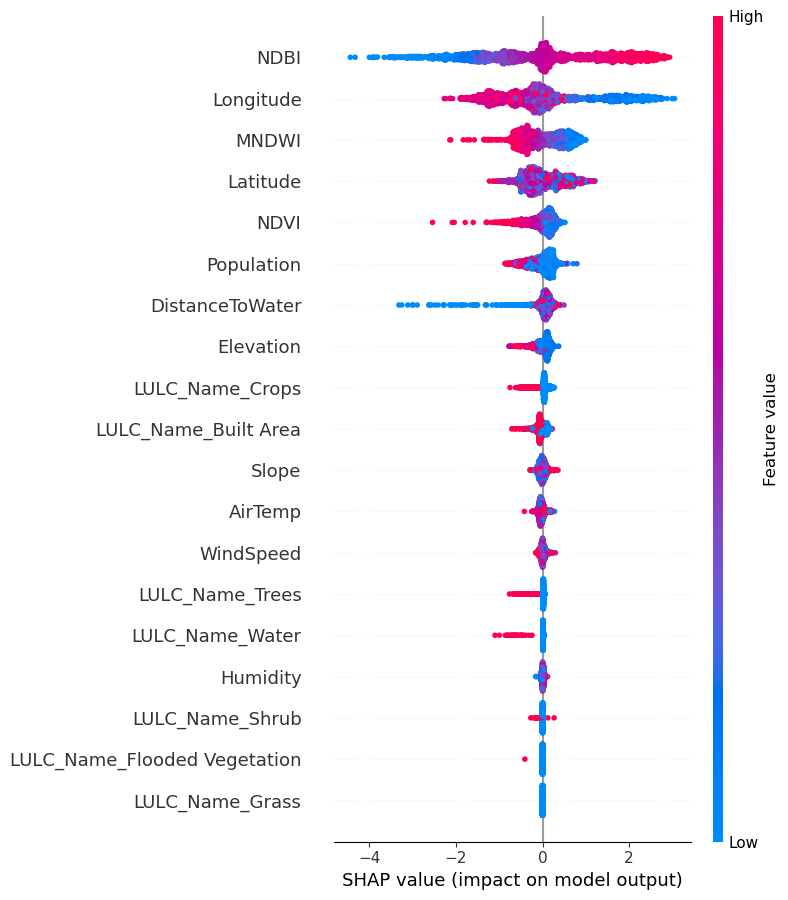

In [15]:
shap.summary_plot(shap_values, X_test)

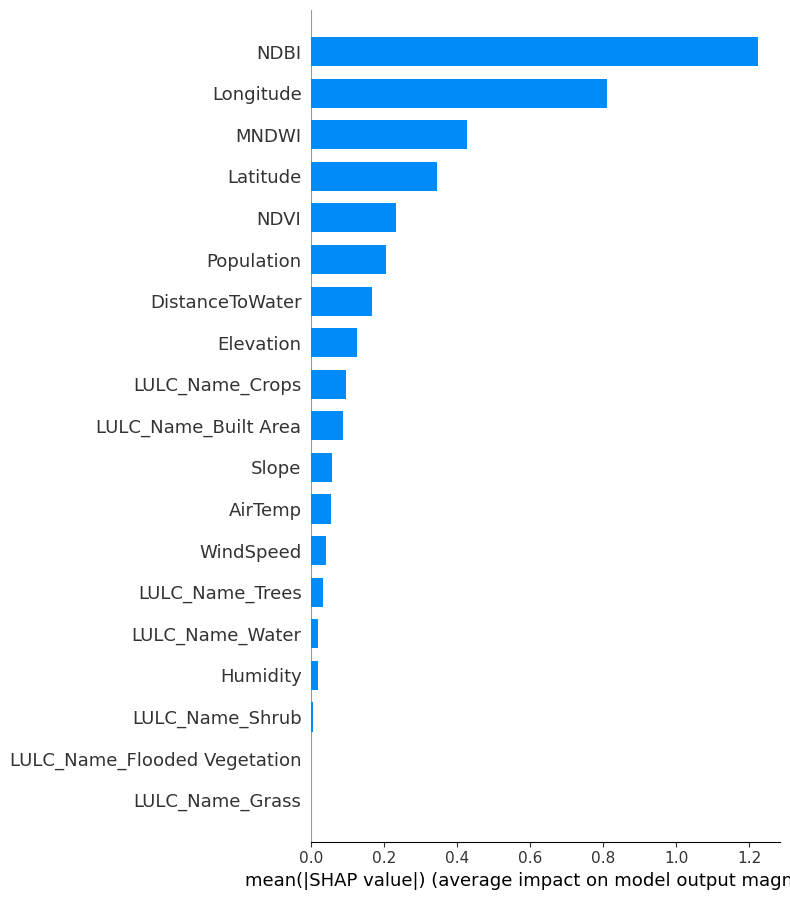

In [16]:
shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar"
)

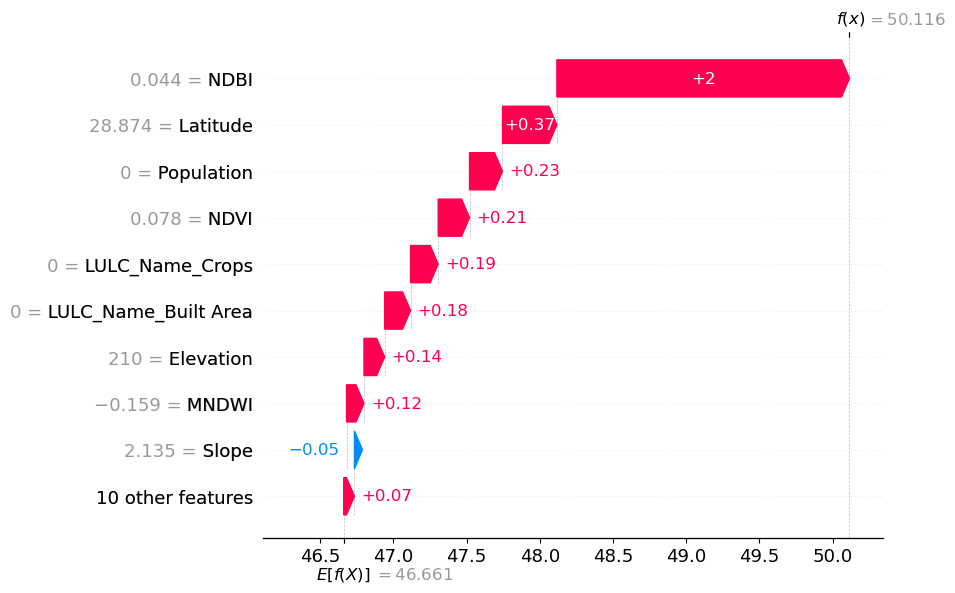

In [17]:
sample = 0
shap.plots.waterfall(
    explainer(X_test.iloc[[sample]])[0]
)

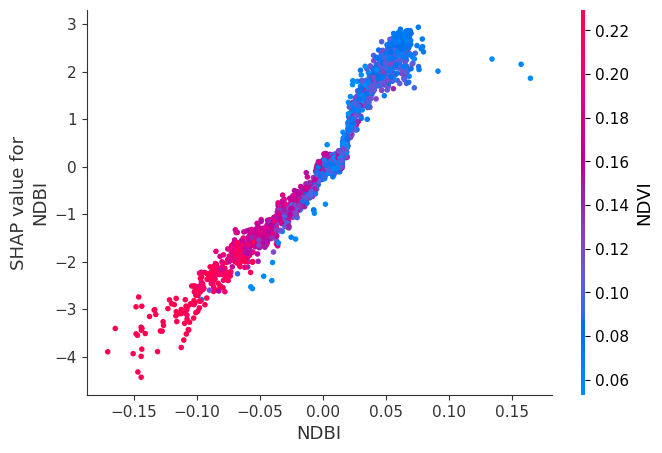

In [18]:
shap.dependence_plot(
    "NDBI",
    shap_values,
    X_test
)

In [21]:
with open(r"C:\Users\kashv\Desktop\Delhi_UHI_Project\Streamlit\best_model.pkl", "wb") as f:
    pickle.dump(best_model,f)

In [23]:
with open(r"C:\Users\kashv\Desktop\Delhi_UHI_Project\Streamlit\features_names.pkl", "wb") as file:
    pickle.dump(X.columns.tolist(),file)